# 04 — Feature Engineering & Baseline Model (DSC LOGIKA UI 2026, Credit Risk)

This notebook takes `base_aggregated.parquet` from notebook 03 and does four things:

1. Fix the **validation strategy** (answers Business Question 3) before any modeling.
2. Add **business-driven & cross-table features** (answers Business Question 1 & 2, grounded in EDA and 03 aggregation).
3. **Select features** (KS filter + correlation pruning) using training data only.
4. Train a **baseline model**, report all metrics, and write a first `submission_baseline.csv`.

Rules for this notebook:
- Every feature uses only information from `base_aggregated`, which was already cut off at each application's `decision_datetime` in notebook 03.
- Anything that uses `target` (KS filter, importance) is computed on the **training part of each fold only**, never on validation rows.
- Same seed, same folds and same `ks_score()` for every experiment.

#### Cell 4.1 — Setup, Seed, Load `base_aggregated`

**What to do:** Set the seed, load the parquet saved by notebook 03 and split it into train and test.

**Why:** Reproducibility and a single entry point for all later cells.

**What to look for:** `train_df` is (70000, 278) and `test_df` is (30000, 278) including an empty `target` column. No duplicate `application_id`.

In [1]:
import os
import random
import platform
import importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score, log_loss, average_precision_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

cwd = os.path.abspath(os.getcwd())
ROOT = cwd if os.path.exists(os.path.join(cwd, "dataset")) else os.path.abspath(os.path.join(cwd, ".."))
DATA_DIR = os.path.join(ROOT, "dataset")
OUT_DIR = os.path.join(ROOT, "output")
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.4f}".format)

parquet_path = os.path.join(OUT_DIR, "base_aggregated.parquet")
pickle_path = os.path.join(OUT_DIR, "base_aggregated.pkl")
base = pd.read_parquet(parquet_path) if os.path.exists(parquet_path) else pd.read_pickle(pickle_path)

USE_LGBM = importlib.util.find_spec("lightgbm") is not None
print("SEED =", SEED, "| python", platform.python_version(), "| pandas", pd.__version__)
print("Model backend:", "LightGBM" if USE_LGBM else "sklearn HistGradientBoosting (lightgbm not installed)")
print("base shape:", base.shape)

assert base["application_id"].is_unique
assert int(base["is_train"].sum()) == 70_000
print("train / test rows:", int(base["is_train"].sum()), "/", int((base["is_train"] == 0).sum()))
print("target rate (train): %.4f" % base.loc[base["is_train"] == 1, "target"].mean())

SEED = 42 | python 3.11.16 | pandas 3.0.6
Model backend: LightGBM
base shape: (100000, 278)
train / test rows: 70000 / 30000
target rate (train): 0.1358


#### Cell 4.2 — Validation Strategy (Business Question 3)

**What to do:** Sort train by `application_datetime` and build three **expanding-window** folds. The last fold is the main holdout: train on the earliest 80%, validate on the latest 20%.

**Why:** Train and test covers 2024-12-27 to 2025-12-28. A random split would let the model see future patterns and overstate KS. A time split mimics what really happens at deployment. Because `customer_id` is unique in all 100,000 rows, there is no same-customer overlap to handle.

**What to look for:** Date ranges that never overlap between train and validation inside each fold, and similar default rates across folds. A clear drift in default rate means the later fold is harder and the KS numbers will drop.

In [2]:
train_df = base[base["is_train"] == 1].sort_values("application_datetime").reset_index(drop=True)
test_df = base[base["is_train"] == 0].reset_index(drop=True)

n = len(train_df)
FOLD_CUTS = [(0.50, 0.65), (0.65, 0.80), (0.80, 1.00)]
folds = []
for train_end, valid_end in FOLD_CUTS:
    tr_idx = np.arange(0, int(n * train_end))
    va_idx = np.arange(int(n * train_end), int(n * valid_end))
    folds.append((tr_idx, va_idx))
MAIN_FOLD = len(folds) - 1

rows = []
for i, (tr, va) in enumerate(folds):
    rows.append({
        "fold": i + 1,
        "train_rows": len(tr),
        "valid_rows": len(va),
        "train_from": train_df.loc[tr[0], "application_datetime"].date(),
        "train_to": train_df.loc[tr[-1], "application_datetime"].date(),
        "valid_from": train_df.loc[va[0], "application_datetime"].date(),
        "valid_to": train_df.loc[va[-1], "application_datetime"].date(),
        "train_default_rate": train_df.loc[tr, "target"].mean(),
        "valid_default_rate": train_df.loc[va, "target"].mean(),
    })
fold_table = pd.DataFrame(rows)
print(fold_table.to_string(index=False))
print("\nTest period:", test_df["application_datetime"].min().date(), "to", test_df["application_datetime"].max().date())

 fold  train_rows  valid_rows train_from   train_to valid_from   valid_to  train_default_rate  valid_default_rate
    1       35000       10500 2024-12-27 2025-06-28 2025-06-28 2025-08-22              0.1357              0.1324
    2       45500       10500 2024-12-27 2025-08-22 2025-08-22 2025-10-17              0.1350              0.1325
    3       56000       14000 2024-12-27 2025-10-17 2025-10-17 2025-12-28              0.1345              0.1411

Test period: 2024-12-27 to 2025-12-28


#### Cell 4.3 — Metric Helper

**What to do:** One function that returns KS (main metric), ROC AUC, Gini, Log Loss and PR AUC.

**Why:** Business Question 3 and the pipeline standard require the same evaluation for every experiment.

**What to look for:** Gini should equal `2 * AUC - 1` exactly. KS should always be at most 1.

In [3]:
def ks_score(y_true, y_score):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    return ks_2samp(y_score[y_true == 1], y_score[y_true == 0]).statistic


def evaluate(y_true, y_score):
    auc = roc_auc_score(y_true, y_score)
    return {
        "KS": ks_score(y_true, y_score),
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "LogLoss": log_loss(y_true, np.clip(y_score, 1e-6, 1 - 1e-6)),
        "PR_AUC": average_precision_score(y_true, y_score),
    }

_demo = evaluate(np.array([0, 0, 1, 1, 0, 1]), np.array([0.1, 0.3, 0.8, 0.6, 0.2, 0.4]))
print({k: round(v, 4) for k, v in _demo.items()})
assert abs(_demo["Gini"] - (2 * _demo["AUC"] - 1)) < 1e-12

{'KS': np.float64(1.0), 'AUC': 1.0, 'Gini': 1.0, 'LogLoss': 0.3892, 'PR_AUC': 1.0}


#### Cell 4.4 — Business-Driven & Cross-Table Feature Engineering (Business Questions 1 & 2)

**What to do:** Build domain-grounded features across six credit-risk pillars using only `base_aggregated` columns (all strictly cut off before `decision_datetime`), label-encode categorical columns, and clean `±inf` values:
1. **Affordability & Debt-Service Burden (Spine × Profile):** DTI (`installment_to_income`), LTI (`loan_to_annual_income`), dependent-adjusted income and installment burden, interest cost ratios, and employment stability (`tenure_to_age`).
2. **Pricing & Loan Escalation (Spine × Previous Applications):** Interest rate markup vs. past loans (`interest_rate_diff_vs_prev`, `interest_rate_ratio_vs_prev`), loan size escalation (`loan_amount_to_prev_requested_mean`), and installment jump (`installment_to_prev_installment`).
3. **Verified Cashflow & Debt Capacity (Account & Bureau × Spine):** Bank-verified income vs. declared income (`verified_to_declared_income`), installment coverage by recent 3-month net cashflow (`installment_to_net_cashflow_3m`) and minimum balance (`installment_to_min_balance_3m`), plus total external + new debt leverage (`total_debt_to_annual_income`, `bur_outstanding_to_income`).
4. **Bureau Trajectory & Score Disagreement (Current vs. Previous Bureau):** Score migration (`bur_score_delta_curr_vs_prev`), inter-bureau dispersion (`bur_score_spread_curr`), utilization shift (`bur_util_delta_curr_vs_prev`), and debt growth (`bur_outstanding_ratio_curr_vs_prev`).
5. **Repayment Deterioration & Compounding Stress (Repayment × Bureau & Spine):** Recent DPD acceleration (`rep_dpd_trend_last3_vs_all`, `rep_dpd30_rate_ratio_last6_vs_all`) and multiplicative stress interactions (`util_x_rep_dpd30_rate`, `util_x_recent_late`, `rep_dpd_x_interest_rate`).
6. **E-Commerce Spending Surge & Lifestyle Inflation (E-Commerce × Spine & Account):** 90-day spending concentration (`ecom_spend_90d_share`), order size acceleration (`ecom_order_accel_90d_vs_older`), recent monthly spend to income (`ecom_monthly_spend_90d_to_income`), share of 3m bank outflows (`ecom_spend_90d_to_outflows_3m`), and joint spending-outflow surge (`ecom_spend_90d_x_outflow_surge`).

**Why:** Notebook 01 & 02 highlight that affordability, historical delinquency, external credit utilization, and pre-application spending surges jointly separate defaulters from good borrowers. Ratios and deltas are also more stationary across time than raw IDR amounts.

**What to look for:** Zero `inf` values, strong univariate KS on the new cross-table features, and preserved row counts (70,000 train / 30,000 test).

In [4]:
def safe_div(a, b):
    if isinstance(b, pd.Series):
        denom = b.replace(0, np.nan)
    else:
        denom = np.where(b == 0, np.nan, b)
    out = a / denom
    return out.replace([np.inf, -np.inf], np.nan)


def add_features(df):
    df = df.copy()
    income = df["declared_monthly_income"]
    annual_income = income * 12

    eng = {}

    # 1. Affordability & Stability (Spine x Profile)
    eng["installment_to_income"] = safe_div(df["proposed_monthly_installment"], income)
    eng["loan_to_annual_income"] = safe_div(df["loan_amount"], annual_income)
    eng["income_per_dependent"] = safe_div(income, df["dependents"] + 1)
    eng["installment_per_dependent_income"] = safe_div(df["proposed_monthly_installment"], eng["income_per_dependent"])
    eng["annual_interest_cost"] = df["loan_amount"] * df["annual_interest_rate"]
    eng["interest_cost_to_income"] = safe_div(eng["annual_interest_cost"], annual_income)
    eng["tenure_years"] = df["employment_tenure_months"] / 12.0
    eng["tenure_to_age"] = safe_div(df["employment_tenure_months"], df["age"] * 12.0)

    # 2. Pricing & Loan Escalation (Spine x Previous Applications)
    eng["interest_rate_diff_vs_prev"] = df["annual_interest_rate"] - df["prev_interest_rate_mean"]
    eng["interest_rate_ratio_vs_prev"] = safe_div(df["annual_interest_rate"], df["prev_interest_rate_mean"])
    eng["loan_amount_to_prev_requested_mean"] = safe_div(df["loan_amount"], df["prev_requested_mean"])
    eng["installment_to_prev_installment"] = safe_div(df["proposed_monthly_installment"], df["prev_installment_mean"])

    # 3. Verified Cashflow & Debt Capacity (Account & Bureau x Spine)
    eng["verified_to_declared_income"] = safe_div(df["acc_income_like_credits_mean_3m"], income)
    eng["installment_to_net_cashflow_3m"] = safe_div(df["proposed_monthly_installment"], df["acc_net_cashflow_mean_3m"])
    eng["installment_to_min_balance_3m"] = safe_div(df["proposed_monthly_installment"], df["acc_minimum_balance_min_3m"] + 1)
    eng["total_debt_to_annual_income"] = safe_div(df["bur_curr_outstanding_max"] + df["loan_amount"], annual_income)
    eng["bur_outstanding_to_income"] = safe_div(df["bur_curr_outstanding_max"], income)

    # 4. Bureau Trajectory & Credit Hunger (Current vs. Previous Bureau)
    eng["bur_score_delta_curr_vs_prev"] = df["bur_curr_score_mean"] - df["bur_prev_score_mean"]
    eng["bur_score_spread_curr"] = df["bur_curr_score_max"] - df["bur_curr_score_min"]
    eng["bur_util_delta_curr_vs_prev"] = df["bur_curr_utilization_mean"] - df["bur_prev_utilization_mean"]
    eng["bur_outstanding_ratio_curr_vs_prev"] = safe_div(df["bur_curr_outstanding_max"], df["bur_prev_outstanding_mean"] + 1)

    # 5. Repayment Deterioration & Compounding Stress (Repayment x Bureau & Spine)
    eng["rep_dpd_trend_last3_vs_all"] = df["rep_max_dpd_mean_last3"] - df["rep_max_dpd_mean_all"]
    eng["rep_dpd30_rate_ratio_last6_vs_all"] = safe_div(df["rep_dpd30_rate_last6"], df["rep_dpd30_rate_all"])
    eng["util_x_rep_dpd30_rate"] = df["bur_curr_utilization_mean"] * df["rep_dpd30_rate_all"]
    eng["util_x_recent_late"] = df["bur_curr_utilization_mean"] * df["rep_late_rate_last3"]
    eng["rep_dpd_x_interest_rate"] = df["rep_max_dpd_mean_all"] * df["annual_interest_rate"]

    # 6. E-Commerce Spending Surge & Lifestyle Inflation (E-Commerce x Spine & Account)
    eng["ecom_spend_90d_share"] = safe_div(df["ecom_spend_last_90d"], df["ecom_total_spend"])
    eng["ecom_order_accel_90d_vs_older"] = safe_div(df["ecom_mean_order_last_90d"], df["ecom_mean_order_older"])
    eng["ecom_monthly_spend_90d_to_income"] = safe_div(df["ecom_spend_last_90d"] / 3.0, income)
    eng["ecom_spend_90d_to_outflows_3m"] = safe_div(df["ecom_spend_last_90d"] / 3.0, df["acc_outflows_mean_3m"])
    eng["ecom_spend_90d_x_outflow_surge"] = df["ecom_spend_last_90d"] * df["acc_outflow_surge_ratio"]

    eng_df = pd.DataFrame(eng, index=df.index).replace([np.inf, -np.inf], np.nan)
    return pd.concat([df, eng_df], axis=1), list(eng_df.columns)


NON_FEATURES = ["application_id", "customer_id", "target", "is_train"]
full, new_cols = add_features(pd.concat([train_df, test_df], ignore_index=True))

# Label-encode text columns (unsupervised, safe to fit on train + test together)
text_cols = [c for c in full.select_dtypes(include=["object", "category", "string"]).columns if c not in NON_FEATURES]
for c in text_cols:
    full[c] = full[c].astype("category").cat.codes.replace(-1, np.nan)
print("Encoded text columns:", text_cols)
print(f"Engineered features added: {len(new_cols)}")

print("\nSummary of engineered features:")
print(full[new_cols].describe().T[["count", "mean", "min", "50%", "max"]])
assert not np.isinf(full[new_cols].to_numpy(dtype=float)).any()

train_df = full[full["is_train"] == 1].iloc[np.argsort(full.loc[full["is_train"] == 1, "application_datetime"].values, kind="stable")].reset_index(drop=True)
test_df = full[full["is_train"] == 0].reset_index(drop=True)
assert len(train_df) == 70_000 and len(test_df) == 30_000

# Time columns are used for splitting only, never as features
DROP_AS_FEATURE = NON_FEATURES + ["application_datetime", "decision_datetime"]
candidate_cols = [c for c in train_df.select_dtypes(include=[np.number]).columns if c not in DROP_AS_FEATURE]
print("\nTotal candidate features:", len(candidate_cols))

Encoded text columns: ['loan_purpose', 'region', 'employment_type', 'housing_status']
Engineered features added: 31

Summary of engineered features:
                                          count           mean          min            50%              max
installment_to_income              100,000.0000         0.2451       0.0503         0.2336           0.8252
loan_to_annual_income              100,000.0000         0.2190       0.0452         0.2090           0.7273
income_per_dependent               100,000.0000 4,544,465.3536 133,653.6000 3,198,819.8750  85,340,951.0000
installment_per_dependent_income   100,000.0000         0.6499       0.0556         0.5652           3.4116
annual_interest_cost               100,000.0000 5,091,122.3200 160,000.0000 3,976,000.0000  63,480,000.0000
interest_cost_to_income            100,000.0000         0.0468       0.0082         0.0435           0.1936
tenure_years                       100,000.0000         4.3006       0.2500         3.6667     

#### Cell 4.5 — Feature Selection (KS Filter + Correlation Pruning)

**What to do:** Inside the **training part of a fold**, drop columns with a very low univariate KS, then keep the highest-KS column from each group of near-duplicates (|Spearman| above 0.95).

**Why:** Notebook 03 showed many near-duplicate repayment aggregates. Removing them makes the model faster, more stable and easier to explain. Selection uses `target`, so it must run per fold on training rows only or validation KS becomes optimistic.

**What to look for:** Candidate features shrinking to a compact, non-redundant set, with columns from several source tables and our newly engineered features retained.

In [5]:
MIN_KS = 0.02
CORR_LIMIT = 0.95


def select_features(train_part, cols, min_ks=MIN_KS, corr_limit=CORR_LIMIT):
    y = train_part["target"].values
    ks_vals = {}
    for c in cols:
        v = train_part[c].values
        mask = ~np.isnan(v)
        if mask.sum() < 100 or np.unique(v[mask]).size < 2:
            continue
        a, b = v[mask][y[mask] == 1], v[mask][y[mask] == 0]
        if len(a) < 30 or len(b) < 30:
            continue
        ks_vals[c] = ks_2samp(a, b).statistic
    ks_series = pd.Series(ks_vals).sort_values(ascending=False)
    ks_series = ks_series[ks_series >= min_ks]

    corr = train_part[ks_series.index].corr(method="spearman").abs()
    kept = []
    for c in ks_series.index:  # highest KS first
        if all(corr.loc[c, k] < corr_limit for k in kept):
            kept.append(c)
    return kept, ks_series


tr_idx, va_idx = folds[MAIN_FOLD]
kept_main, ks_main = select_features(train_df.iloc[tr_idx], candidate_cols)
print(f"Candidates {len(candidate_cols)} -> after KS filter {len(ks_main)} -> after corr pruning {len(kept_main)}")

print("\nTop 15 kept features by univariate KS (main fold, train part only):")
print(ks_main[kept_main].head(15).to_string())

eng_ks = ks_main.reindex([c for c in new_cols if c in ks_main.index]).sort_values(ascending=False)
print("\nEngineered features passing KS filter (main fold, train part):")
print(eng_ks.to_string())

new_in_kept = [c for c in new_cols if c in kept_main]
print(f"\nNew engineered features kept after correlation pruning ({len(new_in_kept)}):", new_in_kept)

Candidates 303 -> after KS filter 218 -> after corr pruning 136

Top 15 kept features by univariate KS (main fold, train part only):
util_x_rep_dpd30_rate     0.4423
rep_dpd_x_interest_rate   0.4421
rep_max_dpd_mean_last6    0.3936
rep_dpd60_rate_all        0.3927
rep_max_dpd_max_all       0.3744
rep_dpd30_rate_last6      0.3730
rep_max_dpd_mean_last3    0.3561
rep_max_dpd_std_last3     0.3518
rep_underpaid_rate_all    0.3395
rep_dpd30_count_all       0.3379
rep_paid_ratio_mean_all   0.3360
rep_dpd90_rate_all        0.3333
rep_dpd_std_last3         0.3195
rep_dpd60_rate_last6      0.3151
rep_dpd30_count_last3     0.2968

Engineered features passing KS filter (main fold, train part):
util_x_rep_dpd30_rate                0.4423
rep_dpd_x_interest_rate              0.4421
util_x_recent_late                   0.3389
ecom_spend_90d_x_outflow_surge       0.2792
rep_dpd_trend_last3_vs_all           0.2612
ecom_spend_90d_share                 0.2557
ecom_monthly_spend_90d_to_income     0.2527


#### Cell 4.6 — Baseline Model on Expanding-Window Folds

**What to do:** For each fold, run selection on the train part, fit a gradient boosting model with fixed hyperparameters (no early stopping on validation), and score the validation part.

**Why:** Gives one honest baseline number to beat. Fixed `n_estimators` avoids tuning on the validation rows.

**What to look for:** Main-fold (fold 3) KS is your headline number. A large gap between folds (for example fold 1 much higher than fold 3) signals drift over time. Train KS far above validation KS signals overfitting.

In [6]:
def make_model(seed=SEED):
    if USE_LGBM:
        import lightgbm as lgb
        return lgb.LGBMClassifier(
            n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=100,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
            random_state=seed, n_jobs=-1, verbose=-1,
        )
    from sklearn.ensemble import HistGradientBoostingClassifier
    return HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=5.0, random_state=seed,
    )


results = []
fold_models = {}
for i, (tr_idx, va_idx) in enumerate(folds):
    tr, va = train_df.iloc[tr_idx], train_df.iloc[va_idx]
    feats, _ = select_features(tr, candidate_cols)
    model = make_model()
    model.fit(tr[feats], tr["target"])
    p_tr = model.predict_proba(tr[feats])[:, 1]
    p_va = model.predict_proba(va[feats])[:, 1]
    m = evaluate(va["target"], p_va)
    m.update({"fold": i + 1, "n_features": len(feats), "train_KS": ks_score(tr["target"], p_tr)})
    results.append(m)
    fold_models[i] = (model, feats)
    print(f"Fold {i + 1}: valid KS {m['KS']:.4f} | AUC {m['AUC']:.4f} | train KS {m['train_KS']:.4f} | features {len(feats)}")

results_df = pd.DataFrame(results).set_index("fold")[["n_features", "KS", "AUC", "Gini", "LogLoss", "PR_AUC", "train_KS"]]
print()
print(results_df.to_string())
print("\nMean KS across folds: %.4f (std %.4f)" % (results_df["KS"].mean(), results_df["KS"].std()))
print("Main holdout (fold %d) KS: %.4f" % (MAIN_FOLD + 1, results_df.loc[MAIN_FOLD + 1, "KS"]))

Fold 1: valid KS 0.5044 | AUC 0.8271 | train KS 0.7335 | features 139
Fold 2: valid KS 0.4988 | AUC 0.8250 | train KS 0.6939 | features 140
Fold 3: valid KS 0.4803 | AUC 0.8182 | train KS 0.6634 | features 136

      n_features     KS    AUC   Gini  LogLoss  PR_AUC  train_KS
fold                                                            
1            139 0.5044 0.8271 0.6542   0.3017  0.4629    0.7335
2            140 0.4988 0.8250 0.6500   0.3051  0.4440    0.6939
3            136 0.4803 0.8182 0.6364   0.3204  0.4583    0.6634

Mean KS across folds: 0.4945 (std 0.0126)
Main holdout (fold 3) KS: 0.4803


#### Cell 4.7 — Importance by Source Table (Business Question 2)

**What to do:** Take the main-fold model and rank features by importance, then sum importance per source table.

**Why:** Answers how much the credit bureau data contributes compared with internal account data, and whether the new ratios and cross-table interactions matter.

**What to look for:** Which source tables carry the model. If the model leans only on `repayment_history`, check whether the other tables add anything by training a version without them.

Top 25 features by model importance:
                                 importance            source_table
bur_curr_score_mean                  0.0238     bureau_observations
ecom_days_since_last_order           0.0236  ecommerce_transactions
ecom_days_since_first_order          0.0223  ecommerce_transactions
days_since_last_prev_app             0.0197   previous_applications
installment_to_prev_installment      0.0191              engineered
bur_curr_score_Bureau_A              0.0191     bureau_observations
rep_dpd_x_interest_rate              0.0179              engineered
ecom_min_order                       0.0175  ecommerce_transactions
bur_curr_score_Bureau_B              0.0161     bureau_observations
ecom_orders_older                    0.0159  ecommerce_transactions
bur_curr_score_Bureau_C              0.0155     bureau_observations
ecom_spend_last_90d                  0.0153  ecommerce_transactions
rep_installment_count_all            0.0141       repayment_history
bur_score_d

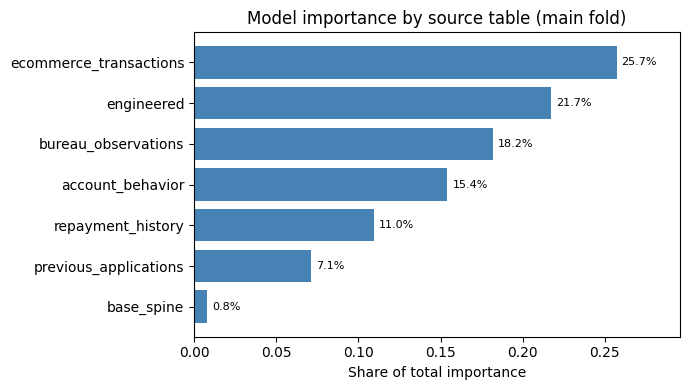

In [7]:
model, feats = fold_models[MAIN_FOLD]
va = train_df.iloc[folds[MAIN_FOLD][1]]

if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=feats)
else:
    from sklearn.inspection import permutation_importance
    sample = va.sample(min(5000, len(va)), random_state=SEED)
    pi = permutation_importance(model, sample[feats], sample["target"], scoring="roc_auc", n_repeats=3, random_state=SEED)
    imp = pd.Series(pi.importances_mean, index=feats)
imp = (imp / imp.sum()).sort_values(ascending=False)

lb_path = os.path.join(OUT_DIR, "ks_leaderboard_aggregated.csv")
if os.path.exists(lb_path):
    source_map = pd.read_csv(lb_path).set_index("column_name")["source_table"].to_dict()
else:
    source_map = {}
source_map.update({c: "base_spine" for c in text_cols})
source_map.update({c: "engineered" for c in new_cols})

imp_table = pd.DataFrame({"importance": imp, "source_table": [source_map.get(c, "other") for c in imp.index]})
print("Top 25 features by model importance:")
print(imp_table.head(25).to_string())

by_source = imp_table.groupby("source_table")["importance"].sum().sort_values()
print("\nImportance share by source table:")
print(by_source.sort_values(ascending=False).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(by_source.index, by_source.values, color="steelblue")
for y_pos, val in enumerate(by_source.values):
    ax.text(val + 0.003, y_pos, f"{val:.1%}", va="center", fontsize=8)
ax.set_xlim(0, by_source.max() * 1.15)
ax.set_xlabel("Share of total importance")
ax.set_title("Model importance by source table (main fold)")
plt.tight_layout()
plt.show()

#### Cell 4.8 — Baseline Submission and Save Outputs

**What to do:** Select features on all 70,000 train rows, fit the baseline, predict test, validate the submission format and save `submission_baseline.csv` plus the feature list.

**Why:** Gives you a valid file early, and notebook 05 can compare every improvement against this baseline.

**What to look for:** 30,000 rows, each `application_id` once, all probabilities between 0 and 1, no NaN. The mean predicted probability should be near the train default rate (about 0.135).

In [8]:
final_feats, _ = select_features(train_df, candidate_cols)
final_model = make_model()
final_model.fit(train_df[final_feats], train_df["target"])
test_pred = np.clip(final_model.predict_proba(test_df[final_feats])[:, 1], 0.0, 1.0)

submission = pd.DataFrame({"application_id": test_df["application_id"].values, "default_probability": test_pred})

assert len(submission) == 30_000
assert submission["application_id"].is_unique
assert submission["default_probability"].between(0, 1).all()
assert submission["default_probability"].notna().all()

submission.to_csv(os.path.join(OUT_DIR, "submission_baseline.csv"), index=False)
pd.Series(final_feats, name="feature").to_csv(os.path.join(OUT_DIR, "selected_features_v1.csv"), index=False)
results_df.to_csv(os.path.join(OUT_DIR, "baseline_cv_results.csv"))

full.to_parquet(os.path.join(OUT_DIR, "features_v1.parquet"), index=False)
print("File full feature berhasil disimpan ke:", os.path.join(OUT_DIR, "features_v1.parquet"))

print("Final features:", len(final_feats))
print("Predicted mean: %.4f | train default rate: %.4f" % (test_pred.mean(), train_df["target"].mean()))
print(submission.head())
print("\nSaved submission_baseline.csv, selected_features_v1.csv, baseline_cv_results.csv to", OUT_DIR)

File full feature berhasil disimpan ke: c:\Users\pevan\Documents\Rado\codingding\githubprojects\lending-money-probability\output\features_v1.parquet
Final features: 132
Predicted mean: 0.1345 | train default rate: 0.1358
       application_id  default_probability
0  A_779e4e5a0ca90902               0.0204
1  A_289cbaf13ec58feb               0.0822
2  A_172169d79a3f4a35               0.0128
3  A_51ff46a3e1427786               0.5748
4  A_bd7e505dcbebaf89               0.3100

Saved submission_baseline.csv, selected_features_v1.csv, baseline_cv_results.csv to c:\Users\pevan\Documents\Rado\codingding\githubprojects\lending-money-probability\output


## Next steps (notebook 05)

- Check train versus test drift per feature (the test period is Jul to Dec 2023) and drop features that drift strongly.
- Tune hyperparameters on the expanding-window folds above, then try a second model family (e.g., CatBoost / XGBoost) and blend by rank average.
- Compare against this baseline using the same `evaluate()` and the same folds.